Códigos sin polígono a 110m (islas pequeñas): ['SGP']


Guardado en D:\EQUIPO\Documents HDD\Tesis\denv-cross-inmunity\figures\mapa_mundial_dengue_silueta.png


Guardado en D:\EQUIPO\Documents HDD\Tesis\denv-cross-inmunity\figures\mapa_mundial_dengue.png


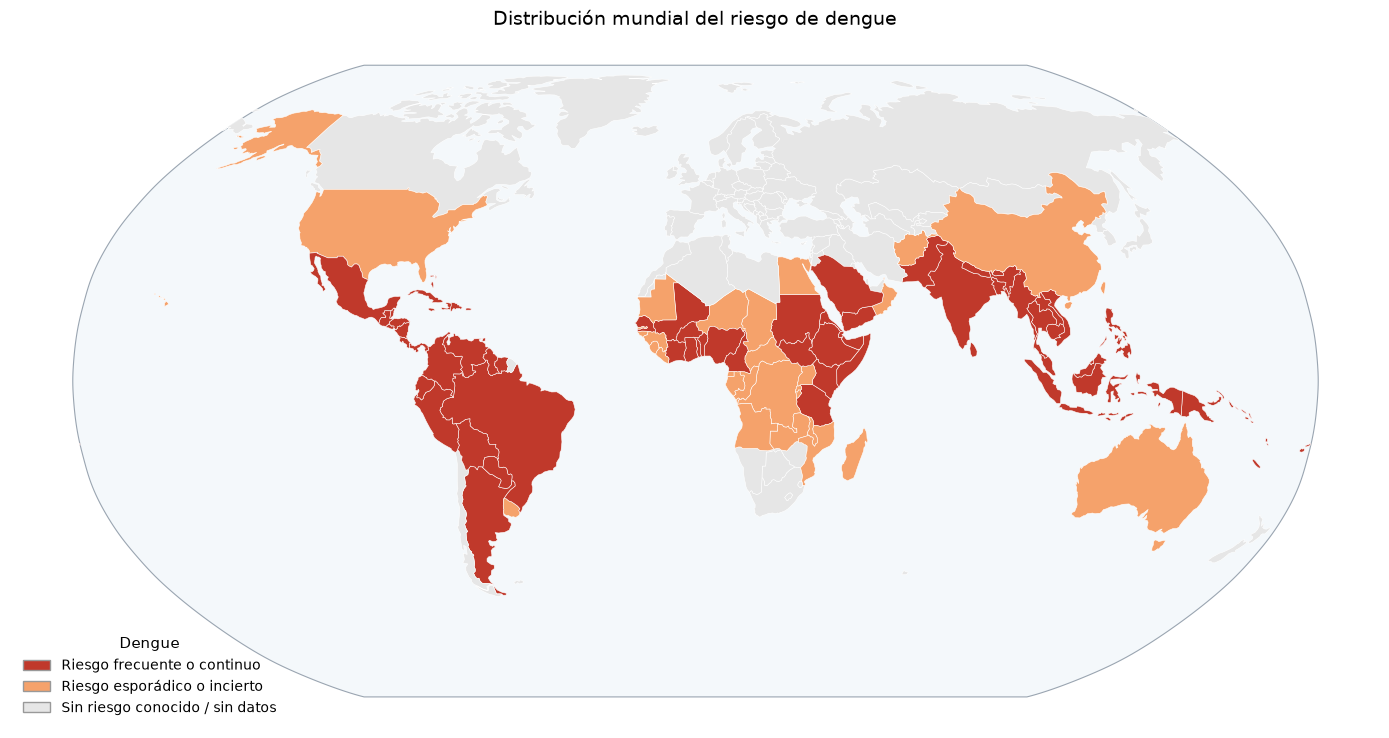

In [1]:
# Mapa mundial de riesgo de dengue (proyección Robinson)
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
from shapely.geometry import Polygon

ROOT = Path.cwd() if (Path.cwd() / "resources").exists() else Path.cwd().parent
NE_ZIP = ROOT / "resources" / "natural_earth" / "ne_110m_admin_0_countries.zip"
OUT = ROOT / "figures" / "mapa_mundial_dengue.png"
OUT_SILUETA = ROOT / "figures" / "mapa_mundial_dengue_silueta.png"

# Clasificación por país (ISO-3), aproximada a partir del mapa de riesgo de dengue
# del CDC Yellow Book y los reportes de la OMS/OPS (2023-2025).
# "frecuente": transmisión frecuente o continua; "esporadico": esporádica o incierta.
FRECUENTE = {
    # Américas
    "MEX", "GTM", "BLZ", "HND", "SLV", "NIC", "CRI", "PAN", "CUB", "DOM", "HTI", "JAM",
    "PRI", "TTO", "BHS", "COL", "VEN", "GUY", "SUR", "BRA", "ECU", "PER", "BOL", "PRY", "ARG",
    # África
    "SDN", "SSD", "ETH", "ERI", "DJI", "SOM", "SOL", "KEN", "TZA", "BFA", "CIV", "GHA", "NGA",
    "CMR", "SEN", "MLI", "TGO", "BEN",
    # Asia y Medio Oriente
    "IND", "PAK", "BGD", "NPL", "BTN", "LKA", "MMR", "THA", "LAO", "KHM", "VNM", "MYS",
    "SGP", "BRN", "IDN", "PHL", "TLS", "SAU", "YEM",
    # Oceanía
    "PNG", "SLB", "VUT", "FJI", "NCL",
}
ESPORADICO = {
    # Américas
    "USA", "URY",
    # África
    "MRT", "GMB", "GNB", "GIN", "SLE", "LBR", "NER", "TCD", "CAF", "GAB", "GNQ", "COG",
    "COD", "UGA", "RWA", "BDI", "AGO", "ZMB", "MWI", "MOZ", "MDG", "EGY",
    # Asia y Medio Oriente
    "CHN", "TWN", "AFG", "OMN",
    # Oceanía
    "AUS",
}

COLORES = {
    "frecuente": "#c0392b",
    "esporadico": "#f5a26b",
    "sin_riesgo": "#e6e6e6",
}
ETIQUETAS = {
    "frecuente": "Riesgo frecuente o continuo",
    "esporadico": "Riesgo esporádico o incierto",
    "sin_riesgo": "Sin riesgo conocido / sin datos",
}

world = gpd.read_file(NE_ZIP)
# Natural Earth deja ISO_A3 = -99 en algunos países (Francia, Noruega...); ADM0_A3 es más completo
iso = world["ISO_A3"].where(world["ISO_A3"] != "-99", world["ADM0_A3"])
world["riesgo"] = "sin_riesgo"
world.loc[iso.isin(ESPORADICO), "riesgo"] = "esporadico"
world.loc[iso.isin(FRECUENTE), "riesgo"] = "frecuente"
world = world[world["ADM0_A3"] != "ATA"]  # sin Antártida

no_encontrados = (FRECUENTE | ESPORADICO) - set(iso)
print("Códigos sin polígono a 110m (islas pequeñas):", sorted(no_encontrados))

world_rob = world.to_crs("ESRI:54030")  # Robinson

fig, ax = plt.subplots(figsize=(14, 7.5))
world_rob.plot(ax=ax, color=world_rob["riesgo"].map(COLORES),
               edgecolor="white", linewidth=0.4)

# Contorno del globo en Robinson
lons = np.r_[np.full(181, -180), np.linspace(-180, 180, 361), np.full(181, 180), np.linspace(180, -180, 361)]
lats = np.r_[np.linspace(-90, 90, 181), np.full(361, 90), np.linspace(90, -90, 181), np.full(361, -90)]
globo = gpd.GeoSeries([Polygon(zip(lons, lats))], crs="EPSG:4326").to_crs("ESRI:54030")
globo.plot(ax=ax, facecolor="#f4f8fb", edgecolor="#9aa5b1", linewidth=0.8, zorder=0)

ax.set_axis_off()
# Solo la silueta: sin leyenda ni título, fondo transparente
fig.savefig(OUT_SILUETA, dpi=300, bbox_inches="tight", pad_inches=0.02, transparent=True)
print("Guardado en", OUT_SILUETA)

ax.legend(handles=[Patch(facecolor=COLORES[k], edgecolor="#999", label=ETIQUETAS[k]) for k in COLORES],
          loc="lower left", frameon=False, fontsize=10, title="Dengue", title_fontsize=11)
ax.set_title("Distribución mundial del riesgo de dengue", fontsize=14)
fig.tight_layout()
fig.savefig(OUT, dpi=300, bbox_inches="tight")
print("Guardado en", OUT)


## Árbol de genotipos de referencia de DENV

Un representante por genotipo, con las ramas pintadas del color de su serotipo.

Representantes canónicos de cada serotipo y genotipo tomados del árbol de
referencia del dataset de Nextclade `nextstrain/dengue/all`, que implementa la
nomenclatura de linajes de Hill et al. (2024). Se conservan
`N_POR_GENOTIPO` secuencias por genotipo y el subárbol inducido se dibuja con
baltic, igual que en `DistancesCalculation.ipynb`.

Las longitudes de rama son las divergencias del build de Nextstrain
(`div` del `tree.json`), escaladas a sustituciones por sitio con la longitud de
la referencia del dataset. Podar el árbol no cambia las distancias entre las
secuencias conservadas.

La versión del dataset está fijada en `NC_TAG` y todo lo descargado queda en
`resources/nextclade_dengue_all/`, de modo que la figura es reproducible.

In [2]:
import json
import random
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from Bio import SeqIO
import baltic as bt

NC_DIR = Path("../resources/nextclade_dengue_all")
VG_DIR = Path("../resources/nextclade_dengue_lineages")
OUT_FIG = Path("../figures")
OUT_TSV = Path("../output")

SERO_COLORS = {1: "#D55E00", 2: "#009E73", 3: "#56B4E9", 4: "#CC79A7"}
COLOR_BACKBONE = "#7F7F7F"   # ramas que mezclan serotipos
N_POR_GENOTIPO = 1
SEMILLA = 20250101

In [3]:
# Descarga del dataset de Nextclade. Solo baja los archivos que falten,
# asi que volver a ejecutar la celda no repite la descarga.
import requests

NC_TAG = "2026-04-14--11-55-23Z"          # version fijada del dataset
NC_BASE = f"https://data.clades.nextstrain.org/v3/nextstrain/dengue/all/{NC_TAG}/"
NC_ARCHIVOS = ["tree.json", "reference.fasta", "genome_annotation.gff3",
               "pathogen.json", "README.md", "CHANGELOG.md"]

NC_DIR.mkdir(parents=True, exist_ok=True)
for nombre in NC_ARCHIVOS:
    destino = NC_DIR / nombre
    if destino.exists():
        print(f"ya estaba: {nombre} ({destino.stat().st_size} bytes)")
        continue
    r = requests.get(NC_BASE + nombre, timeout=180)
    r.raise_for_status()
    destino.write_bytes(r.content)
    print(f"descargado: {nombre} ({len(r.content)} bytes)")

(NC_DIR / "VERSION.txt").write_text(
    f"nextstrain/dengue/all\n{NC_TAG}\n{NC_BASE}\n", encoding="utf8")

# Datasets por serotipo de v-gen-lab (Genome Detective), que asignan el linaje
# de dengue-lineages en clade_membership. Solo se usa su tree.json, para
# derivar la equivalencia entre el genotipo de Nextclade y el linaje nuevo.
VG_TAG = "2026-10-06--17-37-18Z"
VG_BASE = "https://data.clades.nextstrain.org/v3/community/v-gen-lab/dengue/denv{s}/{t}/"

VG_DIR.mkdir(parents=True, exist_ok=True)
for s in SERO_COLORS:
    destino = VG_DIR / f"denv{s}_tree.json"
    if destino.exists():
        print(f"ya estaba: {destino.name} ({destino.stat().st_size} bytes)")
        continue
    r = requests.get(VG_BASE.format(s=s, t=VG_TAG) + "tree.json", timeout=180)
    r.raise_for_status()
    destino.write_bytes(r.content)
    print(f"descargado: {destino.name} ({len(r.content)} bytes)")

(VG_DIR / "VERSION.txt").write_text(
    f"community/v-gen-lab/dengue/denv1-4\n{VG_TAG}\n", encoding="utf8")

ya estaba: tree.json (3442061 bytes)
ya estaba: reference.fasta (10721 bytes)
ya estaba: genome_annotation.gff3 (1741 bytes)
ya estaba: pathogen.json (1910 bytes)
ya estaba: README.md (1087 bytes)
ya estaba: CHANGELOG.md (470 bytes)
ya estaba: denv1_tree.json (663355 bytes)
ya estaba: denv2_tree.json (834534 bytes)
ya estaba: denv3_tree.json (351875 bytes)
ya estaba: denv4_tree.json (450219 bytes)


57

In [4]:
def leer_arbol_auspice(path):
    """Aplana el tree.json de Auspice a una lista de nodos con padre."""
    raiz = json.loads(Path(path).read_text(encoding="utf8"))["tree"]
    nodos, n_id = {}, [0]

    def attr(n, k):
        v = n.get("node_attrs", {}).get(k)
        return v.get("value") if isinstance(v, dict) else v

    def walk(n, padre):
        nid = n.get("name") or f"_n{n_id[0]}"
        n_id[0] += 1
        nodos[nid] = {
            "padre": padre,
            "hijos": [],
            "div": n.get("node_attrs", {}).get("div", 0.0),
            "genotipo": attr(n, "genotype_nextclade"),
            "serotipo": attr(n, "serotype_genbank"),
            "pais": attr(n, "country"),
            "accesion": attr(n, "genbank_accession"),
            "hoja": "children" not in n,
        }
        if padre is not None:
            nodos[padre]["hijos"].append(nid)
        for ch in n.get("children", []):
            walk(ch, nid)
        return nid

    raiz_id = walk(raiz, None)
    return nodos, raiz_id


def mapa_genotipo_a_linaje(nodos):
    """Equivalencia entre el genotipo de Nextclade y el linaje mayor de
    dengue-lineages (Hill et al., 2024).

    No se escribe a mano: se cruzan las accesiones de GenBank del dataset
    `nextstrain/dengue/all`, que trae `genotype_nextclade`, con las de los
    datasets por serotipo de v-gen-lab, que ya asignan el linaje nuevo en
    `clade_membership`. Para cada genotipo se toma el linaje mayoritario.
    """
    por_acc = {}
    for v in nodos.values():
        if v["hoja"] and v["accesion"] and v["genotipo"]:
            por_acc[v["accesion"].split(".")[0]] = v["genotipo"]

    cuentas = {}
    for sero in SERO_COLORS:
        arbol_vg = json.loads((VG_DIR / f"denv{sero}_tree.json").read_text(encoding="utf8"))
        pila = [arbol_vg["tree"]]
        while pila:
            n = pila.pop()
            if "children" in n:
                pila.extend(n["children"])
                continue
            at = n.get("node_attrs", {})
            linaje = at.get("clade_membership", {})
            linaje = linaje.get("value") if isinstance(linaje, dict) else linaje
            acc = (at.get("INSDC_accession") or "")
            acc = acc.get("value") if isinstance(acc, dict) else acc
            acc = (acc or "").split(".")[0]
            if not linaje or linaje == "unassigned" or acc not in por_acc:
                continue
            m = re.match(r"\d+[IVX]+", linaje)          # solo el linaje mayor
            if m:
                cuentas.setdefault(por_acc[acc], Counter())[m.group(0)] += 1

    tabla = pd.DataFrame([
        {"genotipo_nextclade": g, "linaje_dengue_lineages": c.most_common(1)[0][0],
         "n_apoyo": c.most_common(1)[0][1], "n_total": sum(c.values()),
         "otros": ", ".join(f"{k}:{v}" for k, v in c.most_common()[1:]) or "-"}
        for g, c in sorted(cuentas.items())
    ])
    return dict(zip(tabla["genotipo_nextclade"], tabla["linaje_dengue_lineages"])), tabla


def elegir_representantes(nodos, n_por_genotipo, semilla):
    """n secuencias por genotipo, preferiendo las que traen accesion de GenBank."""
    hojas = {k: v for k, v in nodos.items() if v["hoja"] and v["genotipo"]}
    rng = random.Random(semilla)
    elegidas = []
    for gen in sorted({v["genotipo"] for v in hojas.values()}):
        cand = sorted(k for k, v in hojas.items() if v["genotipo"] == gen)
        con_acc = [k for k in cand if hojas[k]["accesion"]]
        pool = con_acc if len(con_acc) >= n_por_genotipo else cand
        elegidas += rng.sample(pool, min(n_por_genotipo, len(pool)))
    return set(elegidas)


def podar_a_newick(nodos, raiz, conservar, n_sitios):
    """Newick del subarbol inducido por las hojas conservadas.
    Las longitudes de rama son diferencias de div, asi que las distancias
    entre las hojas conservadas son las mismas del arbol completo."""
    vivos = set()
    for h in conservar:
        k = h
        while k is not None and k not in vivos:
            vivos.add(k)
            k = nodos[k]["padre"]

    def construir(k, div_padre):
        hijos = [c for c in nodos[k]["hijos"] if c in vivos]
        largo = (nodos[k]["div"] - div_padre) / n_sitios
        if not hijos:
            return f"{k.replace(':', '_').replace(',', '_').replace(' ', '_')}:{largo:.8f}"
        if len(hijos) == 1:                      # colapsa nodos de un solo hijo
            return construir(hijos[0], div_padre)
        partes = ",".join(construir(c, nodos[k]["div"]) for c in hijos)
        return f"({partes}):{largo:.8f}"

    return construir(raiz, nodos[raiz]["div"]) + ";"


def dibujar_arbol(ax, arbol, color, grosor, tam_punta=200, zorder=10):
    """Dibuja el arbol desde k.x / k.y de baltic, como en DistancesCalculation."""
    segs, cols, anchos = [], [], []
    px, py, pc = [], [], []
    for k in arbol.Objects:
        x, y = k.x, k.y
        x_padre = getattr(getattr(k, "parent", None), "x", None)
        if x_padre is None:
            x_padre = x
        c, w = color(k), grosor(k)
        segs.append([(x_padre, y), (x, y)])
        cols.append(c)
        anchos.append(w)
        if k.branchType == "node":
            ys = [ch.y for ch in k.children]
            segs.append([(x, min(ys)), (x, max(ys))])
            cols.append(c)
            anchos.append(w)
        else:
            px.append(x)
            py.append(y)
            pc.append(c)
    ax.add_collection(LineCollection(segs, colors=cols, linewidths=anchos,
                                     capstyle="round", zorder=zorder))
    ax.scatter(px, py, s=tam_punta, c=pc, edgecolors="#333333",
               linewidths=1.5, zorder=zorder + 2)
    ax.autoscale_view()

### Nomenclatura, representantes y figura

Las puntas se etiquetan con el linaje mayor de **dengue-lineages**
(Hill et al., 2024), en números romanos: nada de `Cosmopolitan` ni `American`.
La equivalencia entre el genotipo de Nextclade y el linaje nuevo no se escribe
a mano: se deriva cruzando las accesiones de GenBank de los dos conjuntos de
datos y se guarda en `output/equivalencia_genotipo_linaje.tsv`.

La tabla de representantes, con accesión, país, genotipo y linaje, queda en
`output/genotipos_referencia_nextclade.tsv`.

genotipo_nextclade linaje_dengue_lineages  n_apoyo  n_total  otros
           DENV1/I                     1I       14       14      -
          DENV1/II                    1II        3        3      -
         DENV1/III                   1III        4        5   1V:1
          DENV1/IV                    1IV        6        6      -
           DENV1/V                     1V       19       25 1VII:6
          DENV2/AA                   2III       26       26      -
          DENV2/AI                     2V        3        3      -
         DENV2/AII                    2IV        2        2      -
          DENV2/AM                     2I        2        2      -
           DENV2/C                    2II       18       18      -
           DENV2/S                    2VI        3        4   2I:1
           DENV3/I                     3I        8        8      -
          DENV3/II                    3II       10       10      -
         DENV3/III                   3III        9        9   

Guardado: ..\figures\arbol_genotipos_referencia.png


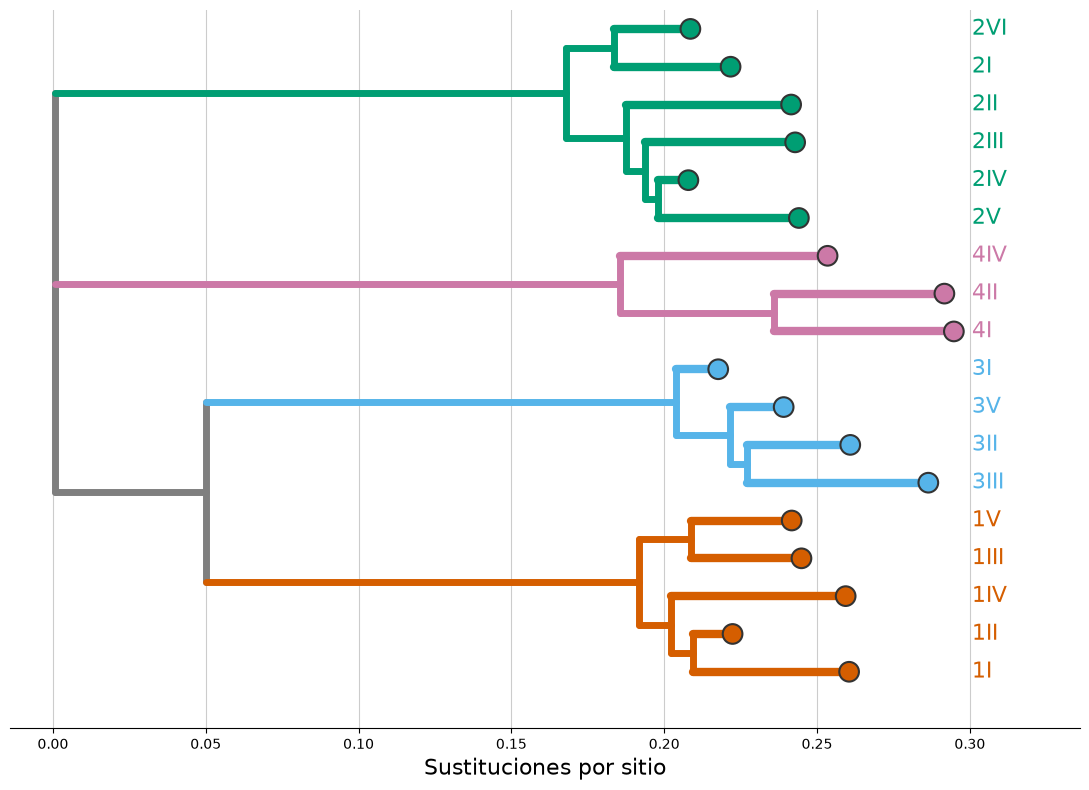

In [5]:
nodos, raiz = leer_arbol_auspice(NC_DIR / "tree.json")

linaje_de, tabla_equivalencias = mapa_genotipo_a_linaje(nodos)
OUT_TSV.mkdir(exist_ok=True)
tabla_equivalencias.to_csv(OUT_TSV / "equivalencia_genotipo_linaje.tsv",
                           sep="\t", index=False)
print(tabla_equivalencias.to_string(index=False))

conservar = elegir_representantes(nodos, N_POR_GENOTIPO, SEMILLA)
print(f"{len(conservar)} representantes de "
      f"{len({nodos[k]['genotipo'] for k in conservar})} genotipos")

# Tabla de representantes, para citar las accesiones en la tesis.
reps = pd.DataFrame([
    {"nombre": k, "linaje": linaje_de.get(nodos[k]["genotipo"], "?"),
     "genotipo_nextclade": nodos[k]["genotipo"],
     "serotipo": nodos[k]["serotipo"], "pais": nodos[k]["pais"],
     "accesion": nodos[k]["accesion"], "div": nodos[k]["div"]}
    for k in sorted(conservar, key=lambda k: (nodos[k]["genotipo"], k))
])
reps.to_csv(OUT_TSV / "genotipos_referencia_nextclade.tsv", sep="\t", index=False)
print(reps.to_string(index=False))

# div viene en sustituciones sobre todo el genoma; se pasa a sustituciones
# por sitio dividiendo por la longitud de la referencia del dataset.
n_sitios = len(next(SeqIO.parse(NC_DIR / "reference.fasta", "fasta")).seq)
print(f"Referencia del dataset: {n_sitios} nt")

newick = podar_a_newick(nodos, raiz, conservar, n_sitios)
nwk_path = NC_DIR / "arbol_genotipos_podado.nwk"
nwk_path.write_text(newick, encoding="utf8")

arbol = bt.load_newick(str(nwk_path), treeType="divergence")
arbol.traverse_tree()
arbol.sort_branches()

# Serotipo y genotipo de cada hoja, por el nombre saneado del newick.
clave = {k.replace(":", "_").replace(",", "_").replace(" ", "_"): k
         for k in conservar}
info = {}
for k in arbol.Objects:
    if k.branchType == "leaf":
        orig = clave[k.name]
        info[k.name] = (int(nodos[orig]["serotipo"].replace("denv", "")),
                        nodos[orig]["genotipo"])

def hojas_de(k):
    if k.branchType == "leaf":
        return [k.name]
    return [d.name if hasattr(d, "name") else d for d in k.leaves]

def color_sero(k):
    s = {info[h][0] for h in hojas_de(k) if h in info}
    return SERO_COLORS[s.pop()] if len(s) == 1 else COLOR_BACKBONE

def grosor(k):
    return 6.0 if k.branchType == "leaf" else 5.0

fig, ax = plt.subplots(figsize=(11, 8))
dibujar_arbol(ax, arbol, color_sero, grosor)

# Una punta por genotipo: la etiqueta es el linaje mayor de dengue-lineages.
x_max = max(k.x for k in arbol.Objects)
for k in arbol.get_external():
    s, g = info[k.name]
    ax.text(x_max * 1.02, k.y, linaje_de.get(g, g), va="center", ha="left",
            fontsize=16, color=SERO_COLORS[s])

ax.set_xlabel("Sustituciones por sitio", fontsize=16)
ax.set_yticks([])
ax.grid(axis="x", color="#CCCCCC", lw=0.8)
ax.set_axisbelow(True)
for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)
ax.set_ylim(-1, len(arbol.get_external()))
ax.set_xlim(right=x_max * 1.14)

fig.tight_layout()
OUT_FIG.mkdir(exist_ok=True)
fig.savefig(OUT_FIG / "arbol_genotipos_referencia.png", dpi=300,
            bbox_inches="tight")
print("Guardado:", OUT_FIG / "arbol_genotipos_referencia.png")

## Proporción de linajes de DENV en Colombia

Réplica del panel A de Rivero et al. (2026): la proporción de cada linaje
frente a la fecha de recolección, con los colores de serotipo de la tesis y la
nomenclatura de dengue-lineages.

Los datos son las secuencias colombianas de `merged_metadata/`, cuya columna
`lineage` ya trae el linaje nuevo (por ejemplo `2III_D.2`); aquí se agrupa por
el linaje mayor (`2III`).

La curva se obtiene con un núcleo gaussiano de `ANCHO_BANDA` años sobre la
fecha de cada secuencia, no interpolando conteos anuales: así cada secuencia
pesa en su fecha real. Donde no hay ninguna secuencia a menos de `HUECO` años
no se dibuja nada, para que el suavizado no rellene periodos sin secuenciar.
Las marcas bajo el eje son las fechas reales de muestreo.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb, to_hex
from matplotlib.patches import Patch
from pathlib import Path

META_MERGED = "merged_metadata/meta_merged_{sero}.tsv"
OUT_FIG = Path("../figures")
OUT_TSV = Path("../output")

SERO_COLORS = {1: "#D55E00", 2: "#009E73", 3: "#56B4E9", 4: "#CC79A7"}

ANCHO_BANDA = 0.75   # desviacion del nucleo gaussiano, en anios
N_REJILLA = 600
HUECO = 1.0          # anios sin ninguna secuencia alrededor -> tramo en blanco

In [7]:
def sombra(color_hex, t):
    """t < 1 aclara mezclando con blanco; t = 1 color base; t > 1 oscurece.
    Misma convencion que shade en AntigenicProjection.ipynb."""
    c = to_rgb(color_hex)
    if t <= 1:
        return to_hex(tuple(1 - t * (1 - v) for v in c))
    return to_hex(tuple(v * (2 - t) for v in c))


def anio_decimal(fechas):
    """Fecha a anio decimal. Las fechas con solo anio se ubican a mitad de anio
    y las de solo mes a mitad de mes, que es la resolucion real del dato."""
    f = fechas.astype(str).str.strip()
    anio = pd.to_numeric(f.str.slice(0, 4), errors="coerce")
    exacta = pd.to_datetime(f, format="mixed", errors="coerce")
    frac = (exacta.dt.dayofyear - 0.5) / np.where(exacta.dt.is_leap_year, 366, 365)
    # sin dia conocido: mitad del mes; sin mes: mitad del anio
    solo_anio = f.str.len() == 4
    solo_mes = f.str.len() == 7
    mes = pd.to_numeric(f.str.slice(5, 7), errors="coerce")
    frac = frac.where(~solo_mes, (mes - 0.5) / 12)
    frac = frac.where(~solo_anio, 0.5)
    return anio + frac


def cargar_colombia():
    """Secuencias colombianas con su linaje mayor y su fecha en anio decimal."""
    filas = []
    for sero in SERO_COLORS:
        df = pd.read_csv(META_MERGED.format(sero=sero), sep="\t", dtype=str)
        df = df[df["country"].fillna("").str.strip().str.lower() == "colombia"].copy()
        # El linaje viene como 2III_D.2; nos quedamos con el linaje mayor.
        df["linaje"] = df["lineage"].astype(str).str.extract(r"^(\d+[IVX]+)")
        df["sero"] = sero
        df["t"] = anio_decimal(df["date"])
        filas.append(df[["strain", "sero", "linaje", "t"]])
    d = pd.concat(filas, ignore_index=True).dropna(subset=["linaje", "t"])
    return d


def proporciones(d, linajes, rejilla):
    """Proporcion de cada linaje a lo largo del tiempo, con un nucleo gaussiano.

    Cada secuencia aporta un peso exp(-0.5 ((t - ti) / ANCHO_BANDA)^2) a su
    linaje. Suavizar asi, en lugar de interpolar conteos anuales, respeta la
    fecha real de cada secuencia y no inventa muestras donde no las hay.
    """
    dt = rejilla[:, None] - d["t"].to_numpy()[None, :]
    w = np.exp(-0.5 * (dt / ANCHO_BANDA) ** 2)
    pesos = np.array([w[:, (d["linaje"] == g).to_numpy()].sum(axis=1) for g in linajes])
    total = pesos.sum(axis=0)
    with np.errstate(invalid="ignore", divide="ignore"):
        prop = np.where(total > 0, pesos / total, np.nan)
    # Sin ninguna secuencia a menos de HUECO anios no se dibuja nada: el
    # suavizado no debe rellenar los periodos en los que no se secuencio.
    sin_dato = np.abs(dt).min(axis=1) > HUECO
    prop[:, sin_dato] = np.nan
    return prop, total

1095 secuencias colombianas, 2000.6-2024.7
linaje
1V      308
2III    291
3III    264
2II     183
4II      48
2IV       1


Guardado: ..\figures\proporcion_linajes_colombia.png
linaje  1V  2II  2III  2IV  3III  4II  TOTAL
anio                                        
2000     0    0     1    0     0    0      1
2001     4    0     5    0     5    7     21
2002     1    0     3    0     8    0     12
2003     0    0     1    0    24    0     25
2004     3    0     5    0     8    5     21
2005     3    0    20    0     7    3     33
2006    26    0     4    0     8    1     39
2007    13    0    11    0    13    0     37
2008    15    0     1    0     1    0     17
2009     7    0     0    0     4    2     13
2010     9    0     7    0    11    4     31
2011     3    0     2    0     0    0      5
2012    14    0    18    0    19    0     51
2013    87    0    38    0    43   14    182
2014     5    0    18    0     7    3     33
2015     9    0    29    0    19    4     61
2016    17    0    29    1    10    3     60
2018     3    0     0    0     0    0      3
2019     5    0     3    0     0    0      8
20

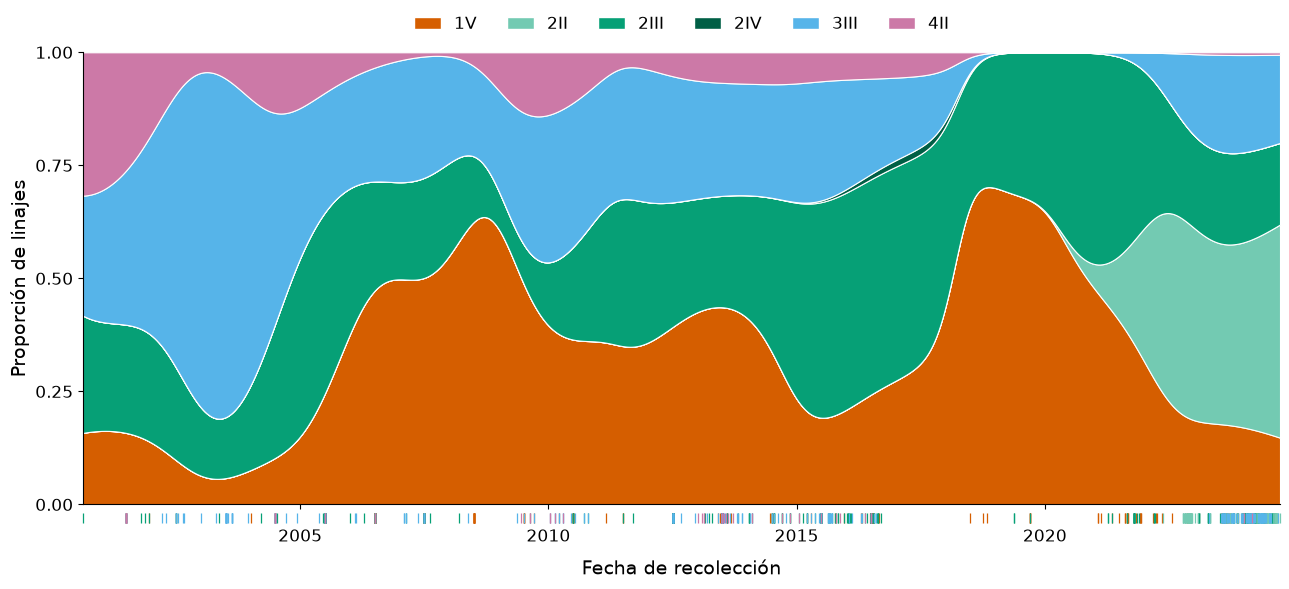

In [8]:
d = cargar_colombia()
print(f"{len(d)} secuencias colombianas, {d['t'].min():.1f}-{d['t'].max():.1f}")
print(d["linaje"].value_counts().to_string())

linajes = sorted(d["linaje"].unique(), key=lambda g: (int(g[0]), g))

# Color: el del serotipo. Si un serotipo aporta varios linajes, se reparten
# en tonos de ese color, de claro a oscuro.
colores = {}
for sero in SERO_COLORS:
    gs = [g for g in linajes if g.startswith(str(sero))]
    for i, g in enumerate(gs):
        t = 1.0 if len(gs) == 1 else 0.55 + 0.85 * (i / (len(gs) - 1))
        colores[g] = sombra(SERO_COLORS[sero], t)

rejilla = np.linspace(d["t"].min(), d["t"].max(), N_REJILLA)
prop, total = proporciones(d, linajes, rejilla)

fig, ax = plt.subplots(figsize=(13, 6))
ax.stackplot(rejilla, np.nan_to_num(prop), colors=[colores[g] for g in linajes],
             edgecolor="white", linewidth=0.8)

# Tramos sin muestreo: se tapan en blanco para no inventar continuidad.
vacio = np.isnan(prop[0])
ax.fill_between(rejilla, 0, 1, where=vacio, color="white", zorder=3)
ax.fill_between(rejilla, 0, 1, where=vacio, color="#F2F2F2", zorder=3.1,
                hatch="///", edgecolor="#D0D0D0", linewidth=0)

# Marcas de las fechas reales de muestreo.
ax.scatter(d["t"], np.full(len(d), -0.03), marker="|", s=60, linewidths=0.9,
           c=[colores[g] for g in d["linaje"]], clip_on=False, zorder=5)

ax.set_xlabel("Fecha de recolección", fontsize=14, labelpad=10)
ax.set_ylabel("Proporción de linajes", fontsize=14)
ax.set_ylim(0, 1)
ax.set_xlim(rejilla[0], rejilla[-1])
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax.tick_params(labelsize=12)
ax.tick_params(axis="x", pad=14)       # deja sitio a las marcas de muestreo
ax.grid(False)
for lado in ["top", "right"]:
    ax.spines[lado].set_visible(False)

ax.legend(handles=[Patch(facecolor=colores[g], edgecolor="white", label=g)
                   for g in linajes],
          loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=len(linajes),
          frameon=False, fontsize=12, handlelength=1.6, columnspacing=1.8)

fig.tight_layout()
OUT_FIG.mkdir(exist_ok=True)
fig.savefig(OUT_FIG / "proporcion_linajes_colombia.png", dpi=300,
            bbox_inches="tight")
print("Guardado:", OUT_FIG / "proporcion_linajes_colombia.png")

# Conteo por año y linaje, para revisar la figura contra el dato crudo.
OUT_TSV.mkdir(exist_ok=True)
tabla = (d.assign(anio=d["t"].astype(int))
           .pivot_table(index="anio", columns="linaje", aggfunc="size", fill_value=0))
tabla["TOTAL"] = tabla.sum(axis=1)
tabla.to_csv(OUT_TSV / "conteo_linajes_colombia_por_anio.tsv", sep="\t")
print(tabla.to_string())

## Proteína E: secuencia y estructura secundaria

Dos diagramas de la proteína E coloreados por dominio, con los sitios
epitópicos que usa la distancia p-all-epitope de `DistancesCalculation.ipynb`
marcados con un triángulo.

Los límites de dominio son la anotación **CATH** de la cadena A de la PDB
`1OAN` (ectodominio soluble de E de DENV2, residuos 1–394). La estructura
secundaria es la **depositada por los autores** en el mmCIF (`struct_conf` para
las hélices, `struct_sheet_range` para las hebras), no un cálculo propio: es la
que respalda la figura publicada de la estructura. El tallo y el anclaje
(395–495) no están en el cristal.

Los colores siguen la convención de la literatura de flavivirus: dominio I
rojo, dominio II amarillo, dominio III azul.

In [9]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrow, Patch
from matplotlib.lines import Line2D
from Bio import SeqIO
import biotite.structure.io.pdbx as pdbx

STRUCT_DIR = Path("../resources/structures")
AA_SEQS_EXP_E_MAP = "../resources/experimental_data/AA_sequences/E_DENV{}_aa_E_map.fasta"
OUT_FIG = Path("../figures")
OUT_TSV = Path("../output")

PDB_ID = "1OAN"          # ectodominio soluble de E de DENV2, residuos 1-394
SERO_REF = 2             # la numeracion de los epitopos es la de DENV1/2/4
E_LEN = 495              # longitud del gen E en DENV1, DENV2 y DENV4

# Colores de dominio: convencion de la literatura de flavivirus
# (Modis et al.: dominio I rojo, dominio II amarillo, dominio III azul).
COL_DOM = {"I": "#C0392B", "II": "#E6C229", "III": "#2E6FAF", "tallo": "#B0B0B0"}
NOMBRE_DOM = {"I": "Dominio I", "II": "Dominio II", "III": "Dominio III",
              "tallo": "Tallo y anclaje"}

# Limites de dominio de CATH sobre 1OAN cadena A (ver docs). El tallo y el
# anclaje (395-495) no estan en la estructura cristalografica.
DOMINIOS = [("I", 1, 51), ("II", 52, 132), ("I", 133, 189), ("II", 190, 267),
            ("I", 268, 294), ("III", 295, 394), ("tallo", 395, E_LEN)]

# Sitios epitopicos de DistancesCalculation.ipynb, tal como estan agrupados alli.
EPITOPOS = {
    "EDI": [[47, 47], [123, 126], [148, 165], [167, 167],
            [170, 177], [180, 180], [279, 279], [293, 293]],
    "EDII": [[67, 74], [76, 79], [88, 88], [97, 118],
             [215, 215], [219, 219], [233, 233], [237, 237],
             [244, 249], [256, 256], [266, 268], [272, 276]],
    "EDIII": [[282, 282], [298, 311], [314, 370],
              [372, 372], [382, 385], [387, 390]],
}

POR_LINEA = 60

In [10]:
# Descarga de la estructura. Solo baja lo que falte.
import requests

STRUCT_DIR.mkdir(parents=True, exist_ok=True)
destino = STRUCT_DIR / f"{PDB_ID}.cif"
if destino.exists():
    print(f"ya estaba: {destino.name} ({destino.stat().st_size} bytes)")
else:
    r = requests.get(f"https://files.rcsb.org/download/{PDB_ID}.cif", timeout=180)
    r.raise_for_status()
    destino.write_bytes(r.content)
    print(f"descargado: {destino.name} ({len(r.content)} bytes)")

# Limites de dominio: anotacion CATH de la cadena A, via la API de RCSB.
# Se descarga para dejar constancia, aunque DOMINIOS ya los recoge arriba.
cath = STRUCT_DIR / f"{PDB_ID}_cath.json"
if not cath.exists():
    r = requests.get(
        f"https://data.rcsb.org/rest/v1/core/polymer_entity_instance/{PDB_ID}/A",
        timeout=180)
    r.raise_for_status()
    cath.write_text(r.text, encoding="utf8")
for a in json.loads(cath.read_text(encoding="utf8")).get(
        "rcsb_polymer_instance_feature", []):
    if a.get("type") == "CATH":
        tramos = ", ".join(f"{p['beg_seq_id']}-{p['end_seq_id']}"
                           for p in a.get("feature_positions", []))
        print(f"  CATH {a.get('feature_id')}  {a.get('name')}: {tramos}")

ya estaba: 1OAN.cif (694421 bytes)
  CATH 2.60.98.10  Tick-borne Encephalitis virus Glycoprotein, domain 1: 1-51
  CATH 2.60.98.10  Tick-borne Encephalitis virus Glycoprotein, domain 1: 133-189
  CATH 2.60.98.10  Tick-borne Encephalitis virus Glycoprotein, domain 1: 268-294
  CATH 3.30.67.10  Viral Envelope Glycoprotein, domain 2: 52-62
  CATH 3.30.67.10  Viral Envelope Glycoprotein, domain 2: 122-132
  CATH 3.30.67.10  Viral Envelope Glycoprotein, domain 2: 190-231
  CATH 3.30.67.10  Viral Envelope Glycoprotein, domain 2: 253-267
  CATH 3.30.387.10  Viral Envelope Glycoprotein, domain 3: 63-121
  CATH 3.30.387.10  Viral Envelope Glycoprotein, domain 3: 232-252
  CATH 2.60.40.350  None: 295-394


In [11]:
def dominio_de(pos):
    for d, a, b in DOMINIOS:
        if a <= pos <= b:
            return d
    return "tallo"


def sitios_epitopicos():
    """Conjunto de posiciones epitopicas y de que grupo viene cada una."""
    pos, grupo = set(), {}
    for g, tramos in EPITOPOS.items():
        for a, b in tramos:
            for p in range(a, b + 1):
                pos.add(p)
                grupo[p] = g
    return sorted(pos), grupo


def estructura_secundaria():
    """Hebras y helices depositadas en el mmCIF de la PDB, cadena A.

    Se usa la anotacion del autor y no un calculo propio: es la que respalda
    la figura publicada de la estructura. Las hebras aparecen repetidas en
    varias hojas, asi que se eliminan los duplicados.
    """
    blk = pdbx.CIFFile.read(STRUCT_DIR / f"{PDB_ID}.cif").block
    elems = []

    sc = blk.get("struct_conf")
    if sc is not None:
        for t, c, a, b in zip(sc["conf_type_id"].as_array(),
                              sc["beg_auth_asym_id"].as_array(),
                              sc["beg_auth_seq_id"].as_array().astype(int),
                              sc["end_auth_seq_id"].as_array().astype(int)):
            if c == "A" and str(t).startswith("HELX"):
                elems.append(("h", int(a), int(b)))

    ss = blk.get("struct_sheet_range")
    if ss is not None:
        vistos = set()
        for c, a, b in zip(ss["beg_auth_asym_id"].as_array(),
                           ss["beg_auth_seq_id"].as_array().astype(int),
                           ss["end_auth_seq_id"].as_array().astype(int)):
            if c == "A" and (int(a), int(b)) not in vistos:
                vistos.add((int(a), int(b)))
                elems.append(("e", int(a), int(b)))

    return sorted(elems, key=lambda x: x[1])


def secuencia_referencia():
    reg = next(iter(SeqIO.parse(AA_SEQS_EXP_E_MAP.format(SERO_REF), "fasta")))
    return reg.id, str(reg.seq)

In [12]:
def leyenda(ax, con_sse=False):
    h = [Patch(facecolor=COL_DOM[d], edgecolor="none", label=NOMBRE_DOM[d])
         for d in ["I", "II", "III", "tallo"]]
    h.append(Line2D([], [], marker="v", color="none", markerfacecolor="black",
                    markeredgecolor="none", markersize=7,
                    label="Sitio epitópico (p-all-epitope)"))
    if con_sse:
        h += [Line2D([], [], marker=">", color="none", markerfacecolor="#555555",
                     markeredgecolor="none", markersize=9, label="Hebra β"),
              Line2D([], [], color="#555555", lw=5, label="Hélice α")]
    ax.legend(handles=h, loc="upper left", bbox_to_anchor=(0, 1.0), ncol=3,
              frameon=False, fontsize=11, handlelength=1.6)


def figura_secuencia(nombre_ref, seq, pos_epi, grupo_epi):
    """Diagrama de la secuencia: cada residuo coloreado por su dominio y los
    sitios epitopicos recuadrados."""
    n_lineas = int(np.ceil(E_LEN / POR_LINEA))
    fig, ax = plt.subplots(figsize=(16, 1.05 * n_lineas + 2.0))

    for li in range(n_lineas):
        ini = li * POR_LINEA + 1
        fin = min(ini + POR_LINEA - 1, E_LEN)
        y = -li * 1.0

        for p in range(ini, fin + 1):
            x = p - ini
            d = dominio_de(p)
            ax.add_patch(Rectangle((x, y), 1, 0.62, facecolor=COL_DOM[d],
                                   edgecolor="none",
                                   alpha=0.45 if p not in pos_epi else 1.0))
            if p in pos_epi:                      # recuadro del sitio epitopico
                ax.add_patch(Rectangle((x, y), 1, 0.62, facecolor="none",
                                       edgecolor="black", lw=0.7, zorder=3))
            aa = seq[p - 1] if p - 1 < len(seq) else " "
            ax.text(x + 0.5, y + 0.31, aa, ha="center", va="center",
                    fontsize=6.4, family="monospace", zorder=4,
                    color="black" if p in pos_epi else "#333333")

        ax.text(-1.2, y + 0.31, f"{ini}", ha="right", va="center", fontsize=9)
        ax.text(POR_LINEA + 1.2, y + 0.31, f"{fin}", ha="left", va="center",
                fontsize=9)
        for p in range(ini, fin + 1):
            if p in pos_epi:
                ax.plot([p - ini + 0.5], [y - 0.1], marker="v", ms=3.2,
                        color="black", clip_on=False)

    ax.set_xlim(-6, POR_LINEA + 6)
    ax.set_ylim(-n_lineas * 1.0 - 0.3, 1.5)
    ax.axis("off")
    ax.set_title(f"Proteína E de DENV ({nombre_ref}) — {len(pos_epi)} sitios "
                 f"epitópicos sobre {E_LEN} residuos", fontsize=13, pad=26)
    leyenda(ax)
    fig.tight_layout()
    OUT_FIG.mkdir(exist_ok=True)
    fig.savefig(OUT_FIG / "proteina_E_secuencia.png", dpi=300, bbox_inches="tight")
    print("Guardado:", OUT_FIG / "proteina_E_secuencia.png")


def figura_estructura_secundaria(elems, pos_epi):
    """Hebras y helices sobre una linea de residuos, coloreadas por dominio."""
    n_lineas = int(np.ceil(E_LEN / POR_LINEA))
    fig, ax = plt.subplots(figsize=(16, 1.5 * n_lineas + 2.2))
    ALTO = 0.40

    for li in range(n_lineas):
        ini = li * POR_LINEA + 1
        fin = min(ini + POR_LINEA - 1, E_LEN)
        y = -li * 1.5

        # Cinta de dominio de fondo y linea de la cadena
        for d, a, b in DOMINIOS:
            a2, b2 = max(a, ini), min(b, fin)
            if a2 <= b2:
                ax.add_patch(Rectangle((a2 - ini, y - 0.30), b2 - a2 + 1, 0.12,
                                       facecolor=COL_DOM[d], edgecolor="none"))
        ax.plot([0, fin - ini + 1], [y, y], color="#999999", lw=1.2, zorder=1)

        # Elementos de estructura secundaria recortados a la linea
        for t, a, b in elems:
            a2, b2 = max(a, ini), min(b, fin)
            if a2 > b2:
                continue
            x, w = a2 - ini, b2 - a2 + 1
            col = COL_DOM[dominio_de((a + b) // 2)]
            # Un elemento partido entre dos lineas lleva la punta de flecha y la
            # etiqueta solo en el tramo donde realmente termina o empieza.
            termina = b2 == b
            empieza = a2 == a
            if t == "e":
                punta = min(3.0, w * 0.45) if termina else 0.0
                ax.add_patch(FancyArrow(x, y, w, 0, width=ALTO,
                                        head_width=ALTO * 1.9 if termina else ALTO,
                                        head_length=punta,
                                        length_includes_head=True,
                                        facecolor=col, edgecolor="#333333",
                                        lw=0.5, zorder=2))
            else:
                ax.add_patch(Rectangle((x, y - ALTO * 0.75), w, ALTO * 1.5,
                                       facecolor=col, edgecolor="#333333",
                                       lw=0.5, zorder=2))
                for xx in np.arange(x + 0.4, x + w - 0.2, 0.8):
                    ax.plot([xx, xx], [y - ALTO * 0.75, y + ALTO * 0.75],
                            color="#333333", lw=0.4, zorder=3)
            if empieza and (b - a + 1) > 6:
                ax.text(x + w / 2, y + ALTO * 1.35, f"{a}–{b}",
                        ha="center", va="bottom", fontsize=6.5, color="#333333")

        # Sitios epitopicos
        for p in range(ini, fin + 1):
            if p in pos_epi:
                ax.plot([p - ini + 0.5], [y - 0.52], marker="v", ms=4.0,
                        color="black", zorder=4)

        ax.text(-1.5, y, f"{ini}", ha="right", va="center", fontsize=9)
        ax.text(fin - ini + 2.5, y, f"{fin}", ha="left", va="center", fontsize=9)

    ax.set_xlim(-7, POR_LINEA + 7)
    ax.set_ylim(-n_lineas * 1.5 - 0.5, 1.9)
    ax.axis("off")
    n_e = sum(1 for t, _, _ in elems if t == "e")
    n_h = sum(1 for t, _, _ in elems if t == "h")
    ax.set_title(f"Estructura secundaria de la proteína E (PDB {PDB_ID}): "
                 f"{n_e} hebras β y {n_h} hélices α", fontsize=13, pad=30)
    leyenda(ax, con_sse=True)
    fig.tight_layout()
    OUT_FIG.mkdir(exist_ok=True)
    fig.savefig(OUT_FIG / "proteina_E_estructura_secundaria.png", dpi=300,
                bbox_inches="tight")
    print("Guardado:", OUT_FIG / "proteina_E_estructura_secundaria.png")

referencia: DENV2/BRAZIL/2004/BR-161 (495 aa)
170 sitios epitopicos
27 hebras, 2 helices
numeracion: 12/13 residuos de control coinciden
  AVISO pos 282: se esperaba V, hay H

11 sitios cuyo grupo del notebook no coincide con CATH:
  EDI: [123, 124, 125, 126] -> CATH ['II']
  EDII: [268, 272, 273, 274, 275, 276] -> CATH ['I']
  EDIII: [282] -> CATH ['I']


Guardado: ..\figures\proteina_E_secuencia.png


Guardado: ..\figures\proteina_E_estructura_secundaria.png


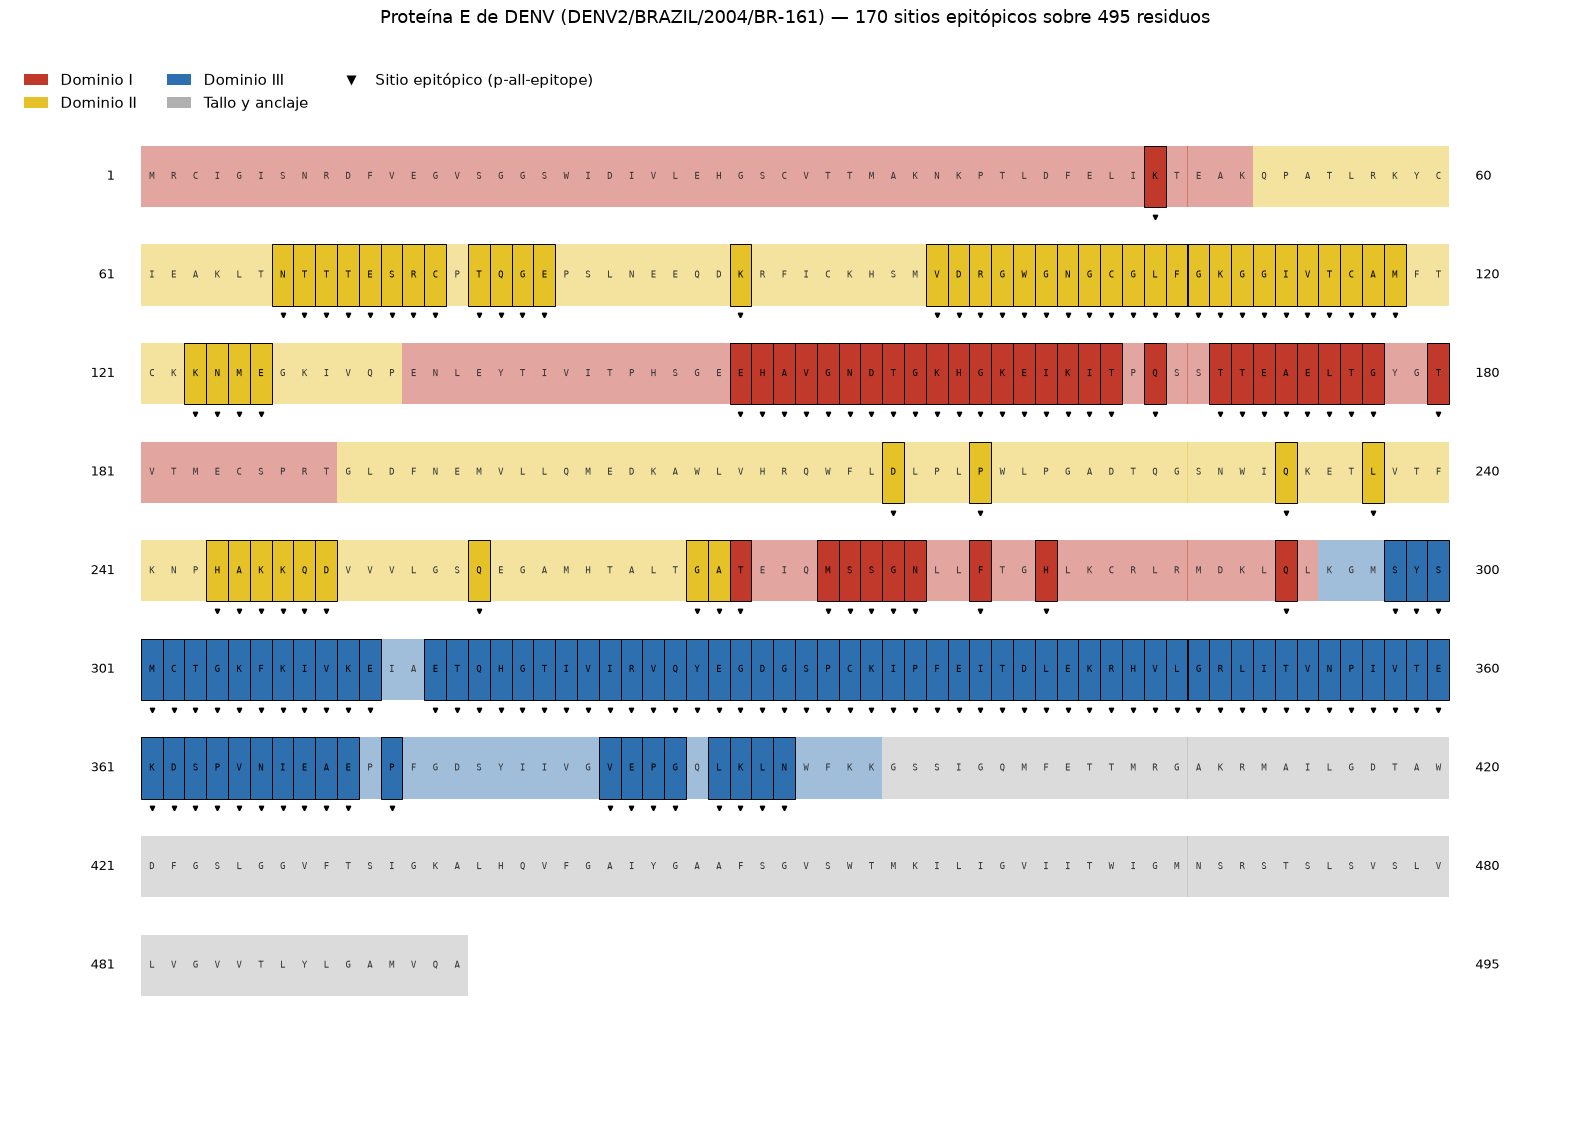

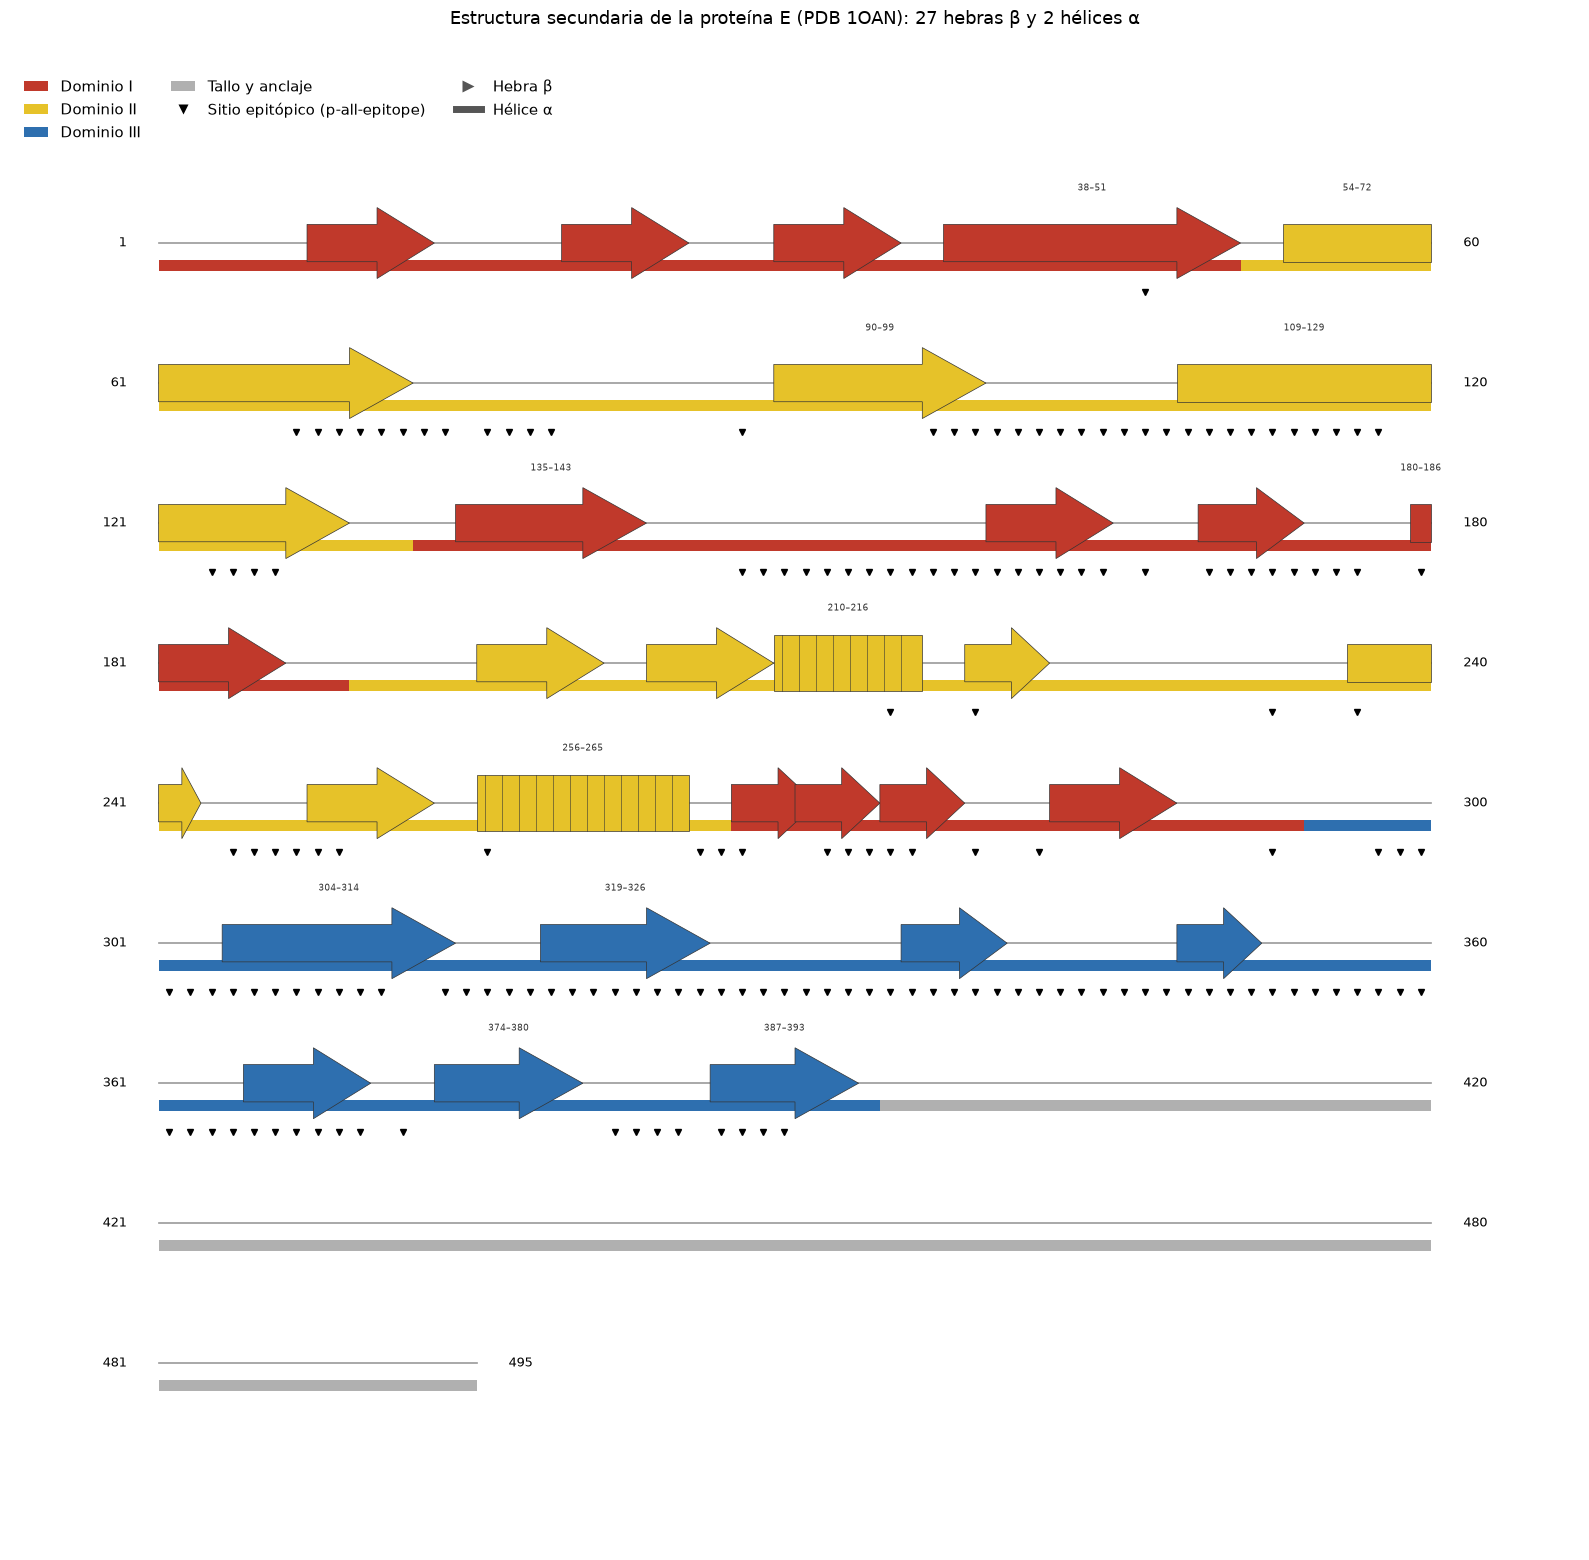

In [13]:
pos_epi, grupo_epi = sitios_epitopicos()
nombre_ref, seq = secuencia_referencia()
elems = estructura_secundaria()
print(f"referencia: {nombre_ref} ({len(seq)} aa)")
print(f"{len(pos_epi)} sitios epitopicos")
print(f"{sum(1 for t, _, _ in elems if t == 'e')} hebras, "
      f"{sum(1 for t, _, _ in elems if t == 'h')} helices")

# Comprobacion de la numeracion: residuos de DENV2 que verifica la celda de
# control de DistancesCalculation.ipynb (anticuerpos DV2-44, DV2-76, 3H2/2C8,
# 1A1D-2 y J8/J9). Si alguno falla, el marco de referencia esta desplazado.
CONTROL = {47: "K", 88: "K", 149: "H", 151: "V", 233: "Q", 244: "H",
           279: "F", 282: "V", 309: "V", 310: "K", 361: "K", 383: "E",
           384: "P"}
malos = {p: (aa, seq[p - 1]) for p, aa in CONTROL.items() if seq[p - 1] != aa}
print(f"numeracion: {len(CONTROL) - len(malos)}/{len(CONTROL)} residuos de "
      f"control coinciden")
for p, (esp, hay) in malos.items():
    # 282 ya falla en la celda de control del propio notebook: las 86
    # secuencias experimentales de DENV2 tienen H en esa posicion.
    print(f"  AVISO pos {p}: se esperaba {esp}, hay {hay}")

# Cotejo entre el dominio estructural (CATH) y el grupo del notebook.
choques = [(p, grupo_epi[p], dominio_de(p)) for p in pos_epi
           if grupo_epi[p].replace("ED", "") != dominio_de(p)]
print(f"\n{len(choques)} sitios cuyo grupo del notebook no coincide con CATH:")
for g in ["EDI", "EDII", "EDIII"]:
    ps = [p for p, gg, _ in choques if gg == g]
    if ps:
        print(f"  {g}: {ps} -> CATH "
              f"{sorted({dominio_de(p) for p in ps})}")

OUT_TSV.mkdir(exist_ok=True)
import pandas as pd
pd.DataFrame({"posicion": pos_epi,
              "grupo_notebook": [grupo_epi[p] for p in pos_epi],
              "dominio_cath": [dominio_de(p) for p in pos_epi],
              "residuo_denv2": [seq[p - 1] for p in pos_epi]}
             ).to_csv(OUT_TSV / "sitios_epitopicos_E.tsv", sep="\t", index=False)

figura_secuencia(nombre_ref, seq, set(pos_epi), grupo_epi)
figura_estructura_secundaria(elems, set(pos_epi))

### Vistas 3D con PyMOL

Los dos scripts de PyMOL están en `scripts/`:

- `pymol_E_monomero.pml`: la cadena A, en tres vistas de cinta más una de
  superficie.
- `pymol_E_dimero.pml`: el dímero «cabeza con cola» (cadenas A y B), en vista
  superior y lateral más una de superficie, como la figura 5 de Sarker et al.
  (2023), que es un esquema y no un renderizado.

El dímero no requiere aplicar simetría: el propio mmCIF declara que el
ensamblaje biológico es dimérico y se obtiene con la operación identidad, así
que las dos cadenas de la unidad asimétrica ya lo forman.

En las vistas de cinta los sitios epitópicos van como esferas sobre el carbono
alfa. En las de superficie el criterio es otro y se lee mejor: el color pleno
del dominio marca lo epitópico y una versión pálida lo que no lo es.

Hace falta **PyMOL de código abierto**; la versión de Schrödinger sin licencia
estampa una marca de agua sobre cada render:

```
conda create -n pymol -c conda-forge pymol-open-source
```

In [14]:
# Ejecuta los dos scripts de PyMOL y recorta el margen blanco de cada imagen.
#
# PyMOL va aparte del entorno del notebook. Hace falta la version de codigo
# abierto, porque la de Schrodinger sin licencia estampa una marca de agua
# sobre cada render:
#     conda create -n pymol -c conda-forge pymol-open-source
import os
import shutil
import subprocess
import sys
from pathlib import Path

from PIL import Image, ImageChops

RAIZ = Path("..").resolve()
PML = ["scripts/pymol_E_monomero.pml", "scripts/pymol_E_dimero.pml"]

# Interprete de un entorno conda llamado "pymol"; se puede fijar a mano.
PYMOL_PY = os.environ.get("PYMOL_PYTHON") or next(
    (str(p) for p in [
        Path.home() / "miniconda3/envs/pymol/python.exe",
        Path("D:/Users/EQUIPO/miniconda3/envs/pymol/python.exe"),
        Path(sys.prefix) / "envs/pymol/python.exe",
    ] if p.exists()), shutil.which("pymol"))

if not PYMOL_PY:
    raise RuntimeError(
        "No se encontro PyMOL. Instalalo con:\n"
        "  conda create -n pymol -c conda-forge pymol-open-source\n"
        "o fija la ruta en la variable de entorno PYMOL_PYTHON.")
print("PyMOL:", PYMOL_PY)

for s in PML:
    r = subprocess.run([PYMOL_PY, "-m", "pymol", "-cq", s],
                       cwd=RAIZ, capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(f"{s} fallo:\n{r.stdout[-2000:]}\n{r.stderr[-2000:]}")
    print(r.stdout.strip().splitlines()[-1])


def recortar(path, margen=12):
    """Quita el margen blanco sobrante que deja el render."""
    im = Image.open(path).convert("RGB")
    fondo = Image.new("RGB", im.size, (255, 255, 255))
    caja = ImageChops.difference(im, fondo).getbbox()
    if caja is None:
        return None
    x0, y0, x1, y1 = caja
    caja = (max(x0 - margen, 0), max(y0 - margen, 0),
            min(x1 + margen, im.width), min(y1 + margen, im.height))
    im.crop(caja).save(path)
    return im.size, (caja[2] - caja[0], caja[3] - caja[1])


for p in sorted((RAIZ / "figures").glob("pymol_E_*.png")):
    r = recortar(p)
    if r:
        print(f"  {p.name}: {r[0][0]}x{r[0][1]} -> {r[1][0]}x{r[1][1]}")

PyMOL: D:\Users\EQUIPO\miniconda3\envs\pymol\python.exe


Monomero listo: 4 imagenes en figures/ y la sesion en resources/structures/


Dimero listo: 3 imagenes en figures/ y la sesion en resources/structures/
  pymol_E_dimero_lateral.png: 2400x2400 -> 2259x531


  pymol_E_dimero_superficie.png: 2400x2400 -> 2352x943
  pymol_E_dimero_superior.png: 2400x2400 -> 2259x844
  pymol_E_monomero_superficie.png: 2200x2200 -> 1870x687


  pymol_E_monomero_vista1.png: 2200x2200 -> 1747x583
  pymol_E_monomero_vista2.png: 2200x2200 -> 1747x583
  pymol_E_monomero_vista3.png: 2200x2200 -> 1747x503
